# Deep Network Development, 2026 Autumn - Week 9 Practice - **Notebook for video recording**

## <font color='red'>Vectorizing arbitrary Python code in NumPy - Rarely useful. Generally, **try to avoid!**</font>

In [1]:
import numpy as np

There is a family of NumPy functions designed to take any Python code and use it in a vectorized manner. One such function is `np.vectorize()`. Many beginner NumPy coders see this function as a holy grail, that is able to produce code with a vectorized behaviour from any Python functions. <font color='red'>**However, these functions merely provide a simple syntactic sugar coating and in reality, they rely on ordinary (and thus inefficient) Python loops.**</font>

Let's see the first example from the documentation of `np.vectorize()`:

In [2]:

# An ordinary Python function defined only for scalar arguments
def myfunc(a, b):
    "Return a-b if a>b, otherwise return a+b"
    if a > b:
        return a - b
    else:
        return a + b

# np.vectorize will produce a "vectorized version" of this Python function.
vfunc = np.vectorize(myfunc)

# Calling this function #1
result1 = vfunc([1, 2, 3, 4], [4, 3, 2, 1])

print(result1)

# Calling this function #2
result2 = vfunc([1, 2, 3, 4], 2)

print(result2)

# Calling this function #3
result3 = vfunc(2, [4, 3, 2, 1])

print(result3)



[5 5 1 3]
[3 4 1 2]
[6 5 4 1]


While the original function expected two scalar arguments, `np.vectorize()` could produce a function `vfunc` which accepted arrays, or a combination of an array and a scalar. The two arguments of `vfunc` are matched in shape via broadcasting and the original function `myfunc` is called in a loop with the matched pairs of elements. The scalars returned by `myfunc` are placed in an appropriately shaped array by `vfunc`.

The `vfunc` function created by `np.vectorize()` implements this behaviour with simple Python loops. Also, if the original function is implemented in an inefficient way by simple Python code, the result will essentially be a loop over the same inefficient function.

The main problem with this approach is that in many cases, a properly vectorized, efficient NumPy solution exists. In this case, the following function can replace `vfunc` and it is significantly more efficient as it is implemented in NumPy:

In [3]:

def efficient_vfunc(a_arr, b_arr):
    # `a_arr` and `b_arr` must be compatible via broadcasting
    a_arr = np.array(a_arr)   # to support list arguments too
    b_arr = np.array(b_arr)   # to support list arguments too
    return np.where(a_arr > b_arr, a_arr - b_arr, a_arr + b_arr)     # np.where() supports the broadcasting of its arguments


# Calling this function #1
result1 = efficient_vfunc([1, 2, 3, 4], [4, 3, 2, 1])

print(result1)

# Calling this function #2
result2 = efficient_vfunc([1, 2, 3, 4], 2)

print(result2)

# Calling this function #3
result3 = efficient_vfunc(2, [4, 3, 2, 1])

print(result3)


[5 5 1 3]
[3 4 1 2]
[6 5 4 1]


**We get the same results but with a vastly more efficient implementation.** Note, that the properly vectorized solution is a completely different approach to the `np.vectorize()` based solution.

Other functions from this family are:
- `np.apply_along_axis()`
- `np.apply_over_axis()`
- `np.frompyfunc()`
- `np.piecewise()`.

**Actual use cases of these functions are:**
- When we have a Python function which has a very complicated logic and we would rather not reimplement it in NumPy as efficiency is not a priority.
- When we have such a Python function which cannot be efficeintly implemented in NumPy. If the algorithm contains a lot of sequential operations that work with little data at a time, often, a NumPy-based solution may not be much more efficient to the naive Python-based solution.
- When we have an external function (perhaps implemented in C/C++, accessed through a Python API) where we have no direct access to the logic. Examples for these are functions from SciPy, OpenCV, Scikit-Image, etc.

... AND we would like to use this function with NumPy features (e.g., broadcasting, fancy indexing) for convenience.

**Even in these cases, do not forget that the "vectorized" functions produced this way are relying on simple Python loops!**

## Computational graphs in PyTorch

In [4]:
import torch

Let's implement a simple expression in PyTorch (the same as the first computational graph example in Lecture 6): $\qquad d = |a\cdot b|$

In [5]:
a = torch.tensor([7.], dtype=torch.float32)
b = torch.tensor([11.], dtype=torch.float32)
c = a * b
d = torch.abs(c)        # d = torch.abs(a * b)

print(d)


# dd_da = torch.autograd.grad(d, a)   # sign(a*b) * b    # raises RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn
                                                         #    --> We did not indicate to PyTorch that we will be computing gradients with respect to these tensors.


tensor([77.])


As we see above, trying to compute $\frac{\partial d}{\partial a}$ using `torch.autograd.grad(d, a)` results in an error which tells us that no computational graph was built as we did not indicate the need for it explicitly. **By default, PyTorch behaves similarly to NumPy:** eager execution will take place and the symbolic connections between variables are not stored.

**We can request the construction of a graph by setting `requires_grad=True` to any of the tensors.** When we use such tensors as arguments in computations, a computational graph is going to be constructed starting from these tensors.

In [6]:
a = torch.tensor([7.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([11.], dtype=torch.float32, requires_grad=True)
c = a * b
d = torch.abs(c)        # d = torch.abs(a * b)

dd_da = torch.autograd.grad(d, a)     # sign(a*b) * b;      Now works!

print('∂d/∂a:', dd_da)     # sign(a*b) * b = sign(7*11) * 11 = 1 * 11 = 11


∂d/∂a: (tensor([11.]),)


Now, `torch.autograd.grad(d, a)` will give us the requested partial derivative in a numerical form. For this, `d` needs to be a result tensor of a series of computations where `a` is one of the inputs and for tensor `a`, `requires_grad=True` must be set.

Let's try to compute now multiple partial derivatives simultaneously!

In [7]:
a = torch.tensor([7.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([11.], dtype=torch.float32, requires_grad=True)
c = a * b
d = torch.abs(c)        # d = torch.abs(a * b)

dd_da = torch.autograd.grad(d, a)     # sign(a*b) * b
# dd_db = torch.autograd.grad(d, b)   # sign(a*b) * a       # raises RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed).
                                                            #                      Saved intermediate values of the graph are freed when you call .backward() or autograd.grad().
                                                            #                      Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.
# dd_dc = torch.autograd.grad(d, c)   # sign(a*b)

print('∂d/∂a:', dd_da)     # sign(a*b) * b = sign(7*11) * 11 = 1 * 11 = 11
#print('∂d/∂b:', dd_db)
#print('∂d/∂c:', dd_dc)



∂d/∂a: (tensor([11.]),)


We see something interesting now: the first call `torch.autograd.grad(d, a)` will work and return the numeric value of $\frac{\partial d}{\partial a}$. However, the subsequent `torch.autograd.grad(d, b)` call will raise an error. From the error message it is easy to figure out what is happening.

In Pytorch, when we request the construction of a graph by specifying `requires_grad=True` to one or more tensors (now `a` and `b`), the graph is constructed from that point forward through all the tensors (now `c` and eventually `d`) that are created from subsequent computations. This is called the forward pass. During this, some of the intermediate results of the computations are kept, as they may be needed during the gradient backpropagation (the backward pass, in other words).

For example, to compute the derivative of the 'absolute value' function (`torch.abs()`), we must know the input, as the derivative will be the elementwise sign of the input. Therefore, even if we did not assign the Python variable `c` to this tensor (which keeps it in memory anyway), the input to this function would still need to be kept in memory for as long as it is required for gradient computation. When we call `torch.autograd.grad(d, a)`, starting from `d` going backwards, the backward functions of the operations are called one by one. They gradually transform the backpropagated gradient until the leaf nodes are reached (in this case these correspond to `a` and `b`). During this backward pass, when a node with a stored intermediate forward result is passed and thus the intermediate result is no longer needed, it will be automatically released from memory. **Due to this, by default, for each graph, only one backward pass is allowed.** Calling `torch.autograd.grad(d, b)` subsequently, thus raises an error as the intermediate forward results that are needed during backpropagation are no longer available.

There are several ways to go around this problem:
1. By passing `retain_graph=True` during the first `torch.autograd.grad(d, a)` call will not release intermediate forward results and therefore, a second call, e.g., `torch.autograd.grad(d, b)` is possible. The memory footprint will of course be much bigger until the intermediate results are released.
2. `torch.autograd.grad()` can be used to calculate multiple partial derivatives at once. For example, `torch.autograd.grad(d, [a, b])` is possible.

If we need to have access to intermediate gradients of unnamed intermediate forward results, we can also register callback functions to certain nodes in the graph that are invoked during a forward or a backward pass. These are called "hooks" in PyTorch.

Using Approach \#1, multiple backward passes are possible:

In [8]:
a = torch.tensor([7.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([11.], dtype=torch.float32, requires_grad=True)
c = a * b
d = torch.abs(c)        # d = torch.abs(a * b)


dd_da = torch.autograd.grad(d, a, retain_graph=True)     # sign(a*b) * b
dd_db = torch.autograd.grad(d, b, retain_graph=True)     # sign(a*b) * a

dd_dc = torch.autograd.grad(d, c)   # sign(a*b)

print('∂d/∂a:', dd_da)    # sign(a*b) * b = sign(7*11) * 11 = 1 * 11 = 11
print('∂d/∂b:', dd_db)    # sign(a*b) * a = sign(7*11) * 7 = 1 * 7 = 7
print('∂d/∂c:', dd_dc)    # sign(a*b) = sign(7*11) = 1



∂d/∂a: (tensor([11.]),)
∂d/∂b: (tensor([7.]),)
∂d/∂c: (tensor([1.]),)


Using Approach \#2, multiple partial derivatives can be computed at once:

In [9]:
a = torch.tensor([7.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([11.], dtype=torch.float32, requires_grad=True)
c = a * b
d = torch.abs(c)        # d = torch.abs(a * b)

dd_da, dd_db = torch.autograd.grad(d, [a, b])     # dd_da = sign(a*b) * b ,      dd_db = sign(a*b) * a

print('∂d/∂a:', dd_da)    # sign(a*b) * b = sign(7*11) * 11 = 1 * 11 = 11
print('∂d/∂b:', dd_db)    # sign(a*b) * a = sign(7*11) * 7 = 1 * 7 = 7



∂d/∂a: tensor([11.])
∂d/∂b: tensor([7.])


Now, let's implement a bit more complex computational graph. We will use the main example from Lecture 6. This is essentially a univariate linear regression model trained on a single example (scalar input and label) using the squared error loss function. **We will perform a single training iteration on this graph and update the parameters. We will use the same numbers as in the lecture slides.**

- First, we build the computational graph by defining how the `loss` tensor is obtained from tensors `w`, `b` (the parameters of the model) and tensors `x`, `y` (the data point). As we have `requires_grad=True` set for `w` and `b`, a graph is constructed starting from these tensors towards `loss`.
- Then, we perform the backward pass by calling `torch.autograd.grad(loss, [w, b])`. This will return the numeric values $\frac{\partial loss}{\partial w}$ and $\frac{\partial loss}{\partial b}$.
- Finally, we compute the parameter updates according to the gradient descent update formula.

The computed gradients and the updated parameter values match the values from Lecture 6.

In [10]:
w = torch.tensor([3.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([4.], dtype=torch.float32, requires_grad=True)

x = torch.tensor([2.], dtype=torch.float32)
y = torch.tensor([5.], dtype=torch.float32)

LEARNING_RATE = 0.1    # denoted by alpha in slides

# Forward pass: Graph is being built starting from tensors `w` and `b`, since these Tensors were initialized with `requires_grad=True`

q = w*x
y_hat = q + b
z = y - y_hat
loss = z ** 2              # `loss` is denoted with J in the lecture slides
                           #     loss = (y - (w*x + b))**2

print(f"w: {w}, b: {b}, x: {x}, y: {y}\n")
print("q:", q)           # 6
print("y_hat:", y_hat)   # 10
print("z:", z)           # -5
print("loss:", loss)     # 25

# Backward pass:

# Instead of setting retain_graph=True and performing backward pass twice, we can specify all leaves with respect to which we need to compute gradients:
dloss_dw, dloss_db = torch.autograd.grad(loss, [w, b])    #    dloss_dw = 2*z * -1 * 1 * x,    dloss_db = 2*z * -1 * 1

print('∂loss/∂w:', dloss_dw)    # dloss_dw = 2*z * -1 * 1 * x = 20
print('∂loss/∂b:', dloss_db)    # dloss_db = 2*z * -1 * 1 = 10

# Update parameters:

w = w - LEARNING_RATE * dloss_dw        # 3 - 0.1 * 20    -> 1
b = b - LEARNING_RATE * dloss_db        # 4 - 0.1 * 10    -> 3

print('Updated w:', w)
print('Updated b:', b)



w: tensor([3.], requires_grad=True), b: tensor([4.], requires_grad=True), x: tensor([2.]), y: tensor([5.])

q: tensor([6.], grad_fn=<MulBackward0>)
y_hat: tensor([10.], grad_fn=<AddBackward0>)
z: tensor([-5.], grad_fn=<SubBackward0>)
loss: tensor([25.], grad_fn=<PowBackward0>)
∂loss/∂w: tensor([20.])
∂loss/∂b: tensor([10.])
Updated w: tensor([1.], grad_fn=<SubBackward0>)
Updated b: tensor([3.], grad_fn=<SubBackward0>)


However, in our typical neural network training loop, we do not call `torch.autograd.grad()` explicitly. Instead, we use the `Tensor.backward()` function to perform backpropagation. The two approaches rely on mostly the same background logic, but will have somewhat different effects.

Pytorch tensors have the `Tensor.grad` attribute which points to another tensor. When using `torch.autograd.grad()`, these are not used. **However, when `Tensor.backward()` is used for performing the backpropagation, to all tensors in the computation where `requires_grad=True` is set, the corresponding `Tensor.grad` attribute will be filled with its gradient.** The `retain_graph=True` argument can be passed to the `Tensor.backward()` function as well: in this case, `Tensor.grad` will be kept for all tensors in the graph (high memory usage!).

One important thing to note is that if some `Tensor.grad` attributes were already present with valid values, these will not be overwritten by the newly computed gradients, but instead, the new gradients will be added to the old values. This behaviour allows parts of the graphs to be trained with multiple loss expressions simultaneously. (Imagine some shared backbone neural network that is used and trained in multiple different computer vision tasks. For each task, a separate network produces the prediction, but these network all rely on outputs from the shared backbone network.) **Due to this accumulating behaviour, when we perform multiple iterations of training, before each iteration we need to set all gradient tensors to zero.** When using one of the built-in Optimizer algorithms, `Optimizer.zero_grad()` will do exactly this for us. Now, we do it by hand.

**After the `loss.backward()` call, we can access the $\frac{\partial loss}{\partial w}$ and $\frac{\partial loss}{\partial b}$ gradients through `w.grad` and `b.grad`.** These will be used to perform the parameter updates.

In [11]:
w = torch.tensor([3.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([4.], dtype=torch.float32, requires_grad=True)

x = torch.tensor([2.], dtype=torch.float32)
y = torch.tensor([5.], dtype=torch.float32)

LEARNING_RATE = 0.1    # denoted by alpha in slides

# Forward pass: Graph is being built starting from tensors `w` and `b`, since these Tensors were initialized with `requires_grad=True`

q = w*x
y_hat = q + b
z = y - y_hat
loss = z ** 2              # `loss` is denoted with J in the lecture slides
                           #     loss = (y - (w*x + b))**2

print(f"w: {w}, b: {b}, x: {x}, y: {y}")
print("q:", q)           # 6
print("y_hat:", y_hat)   # 10
print("z:", z)           # -5
print("loss:", loss)     # 25

# Backward pass:

w.grad = torch.zeros_like(w)    # Zeroing grad tensors is not needed now, as the w and b tensors have just been initialized.
b.grad = torch.zeros_like(b)    #     However, if there had been prior backward() calls, the w.grad, b.grad tensors could contain gradients from previous steps.
                                #     Performing another backward pass would not overwrite, but add new gradients to w.grad, b.grad.
                                # Setting w.grad, b.grad to None is also good.

loss.backward()      # Backpropagates gradients to all leafs of the computational graph and adds them to w.grad, b.grad tensors.

dloss_dw = w.grad    # 2*z * -1 * 1 * x
dloss_db = b.grad    # 2*z * -1 * 1

print('∂loss/∂w:', dloss_dw)    # dloss_dw = 2*z * -1 * 1 * x = 20
print('∂loss/∂b:', dloss_db)    # dloss_db = 2*z * -1 * 1 = 10

# Update parameters:

w = w - LEARNING_RATE * dloss_dw        # 3 - 0.1 * 20    -> 1
b = b - LEARNING_RATE * dloss_db        # 4 - 0.1 * 10    -> 3

print('Updated w:', w)
print('Updated b:', b)


w: tensor([3.], requires_grad=True), b: tensor([4.], requires_grad=True), x: tensor([2.]), y: tensor([5.])
q: tensor([6.], grad_fn=<MulBackward0>)
y_hat: tensor([10.], grad_fn=<AddBackward0>)
z: tensor([-5.], grad_fn=<SubBackward0>)
loss: tensor([25.], grad_fn=<PowBackward0>)
∂loss/∂w: tensor([20.])
∂loss/∂b: tensor([10.])
Updated w: tensor([1.], grad_fn=<SubBackward0>)
Updated b: tensor([3.], grad_fn=<SubBackward0>)


We will change one more thing in our code to be able to see the connection between the low-level and high-level training implementations.

This time, we will use a custom `torch.nn.Module` subclass to define the previous model. But, instead of using built-in layers, we will define the parameters by hand with the `torch.nn.parameter.Parameter` class. **A `Parameter` is a subclass of `Tensor`. It adds two features to regular tensors:**
- `requires_grad` is, by default, set to True in Parameters. Due to this, computations with Parameters will, by default, construct a computational graph.
- When used as a member field of a `torch.nn.Module`, it will automatically be found and registered as a trainable parameter of that model (layer or network). This means, that `torch.nn.Module.parameters()` will include all of these in the returned list of parameter tensors. This can be passed then, to an optimizer, for example.

In [12]:
import torch.nn as nn

We define the same simple model as a `torch.nn.Module` subclass. The two parameters are set as `self.w` and `self.b`.

In [13]:

class MyLittleModel(nn.Module):

  def __init__(self, w_init, b_init):
        # w_init, b_init should be scalars now only
        super().__init__()
        self.w = torch.nn.parameter.Parameter( torch.tensor([w_init], dtype=torch.float32) )       # as this is a Parameter, it will set requires_grad=True automatically.
        self.b = torch.nn.parameter.Parameter( torch.tensor([b_init], dtype=torch.float32) )

  def __str__(self):
    return f"MyLittleModel -> w:     {self.w}, b:     {self.b}"

  def forward(self, x):
    # x should be a scalar now only
    q = self.w*x
    y_hat = q + self.b
    return y_hat


We perform one training step with the model.
- A `MyLittleModel.forward()` call will now define the computational graph until the point where the prediction of the model is obtained.
- The remaining part of the computational graph (the loss function) is defined as the lambda expression (an in-line function) `loss_fn` over the model prediction and the label.
- To set the `.grad` tensors of all parameter tensors to zero, we can iterate through the list returned by `MyLittleModel.parameters()` and set them one by one to an all zero tensor (or `None` is also good). As we only perform a single training iteration now, this step is not needed now.
- The actual call to `MyLittleModel.forward()` and the loss function will perform the forward pass.
- `loss.backward()` will perform the backward pass and populate `MyLittleModel.w.grad` and `MyLittleModel.b.grad`.
- We manually update these weight tensors with their gradient tensors and a learning rate.

In [14]:

LEARNING_RATE = 0.1    # denoted by alpha in slides

# instantiate model, initialize weights
my_little_model = MyLittleModel(w_init = 3., b_init = 4.)

# Print model weights now
print(my_little_model)

# define the loss function - squared error (now as an in-line function, a lambda expression); both inputs and outputs should be scalars now
loss_fn = lambda y_hat, y: (y - y_hat)**2

# get a single data point now to train the model with (instead of a batch)
current_x = 2.
current_y = 5.

# (NOT NEEDED IN THIS CASE) Clear prior gradients: in this case there were no previous steps, but if there had been, we should set all parameter gradient tensors to zero (equivalent: set them to None)
for param in my_little_model.parameters():
    param.grad = None

# Forward pass, compute model estimate then compute loss

current_y_hat = my_little_model(current_x)

loss = loss_fn(current_y_hat, current_y)

# Backward pass: parameter .grad tensors are filled up by the accumulated gradients

loss.backward()

# Update model parameters (manually now, instead of an optimizer)

for param in my_little_model.parameters():
    param.data = param - LEARNING_RATE * param.grad      # a Parameter is a Tensor itself     (a subclass)

# Print model weights after update
print(my_little_model)





MyLittleModel -> w:     Parameter containing:
tensor([3.], requires_grad=True), b:     Parameter containing:
tensor([4.], requires_grad=True)
MyLittleModel -> w:     Parameter containing:
tensor([1.], requires_grad=True), b:     Parameter containing:
tensor([3.], requires_grad=True)


**Graph building criteria:**
- A graph is only built if at least one of the input tensors has its `requires_grad` attribute set to True. If all inputs have `requires_grad=False`, PyTorch will not track the operations, and no graph is built for that specific computation. In this case, PyTorch behaves similarly to NumPy.
- The graph is destroyed immediately after `loss.backward()` is called (or `torch.autograd.grad()`). This frees up memory.
- As the graph is destroyed after each backward pass, a brand-new graph is built from scratch during the next iteration's forward pass. This allows much more flexibility over classical static graphs in TensorFlow version 1.x.
- If `retain_graph=True` is set for a Tensor in the graph, the graph is not going to be destroyed from that Tensor onwards, until the end of the graph.

**Static graphs in PyTorch:**
- `torch.compile()`: Can compile and optimize a computation into a static graph. This can boost the efficiency of a given PyTorch code. _(PyTorch version >= 2)_

**Computation without gradients / ending a graph / detaching a tensor from a graph:**
By default, no graph is constructed and gradients are not computed if there are no tensors in our computations with `requires_grad=True` set. However, it is often the case that we want to compute gradients across a part of our computations, but not for others. A good example for this is a typical training loop of neural networks. We would like to compute gradients for the training loss, and for that, we need to construct a graph starting from the model parameters until the loss expression is reached. However, in our training loop we often would like to build additional computations on our neural network predictions, such as the evaluation of the network on validation and test data, and possibly also on the training data using (possibly non-differentiable) metrics, like accuracy. For such computations we will not need gradients and thus building a graph is not needed. However, additional computations over a graph will, by default, continue to build the graph. To avoid this, and be able to build computations on our graph without continuing the graph itself, we have several options.

`Tensor.detach()` will create and return a new tensor that shares memory with the original tensor for its values, but the returned tensor will have `requires_grad=False` set and it will not be connected to any computational graphs and will also not refer to the `.grad` tensor of the original tensor:


In [15]:
a = torch.tensor([7.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([11.], dtype=torch.float32, requires_grad=True)
c = a * b
d = torch.abs(c.detach())

print("c.requires_grad", c.requires_grad)    # -> True
print("d.requires_grad", d.requires_grad)    # -> False

#dd_da = torch.autograd.grad(d, a)     # Raises RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

dc_da = torch.autograd.grad(c, a)      # OK


c.requires_grad True
d.requires_grad False


An alternative to `Tensor.detach()` is the **`torch.no_grad` context manager.** This can be used either as a decorator to a function (see the binary accuracy defintion) or in a `with` block. All tensors that are created in such blocks will be detached from graphs (`requires_grad=False`).

In [16]:
a = torch.tensor([7.], dtype=torch.float32, requires_grad=True)
b = torch.tensor([11.], dtype=torch.float32, requires_grad=True)
c = a * b

with torch.no_grad():
    d = torch.abs(c)

print("c.requires_grad", c.requires_grad)    # -> True
print("d.requires_grad", d.requires_grad)    # -> False

#dd_da = torch.autograd.grad(d, a)     # Raises RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

dc_da = torch.autograd.grad(c, a)      # OK


c.requires_grad True
d.requires_grad False


Additionally, in PyTorch versions >= 2, an "Inference mode" context is also available. This is somewhat similar to the `no_grad` context, but computations are slightly more efficient and the memory footprint is reduced as graph-related features are completely dropped from tensors and operations. On the other hand, tensors created in such contexts cannot be directly used in graphs.

## Loading data and converting it into a NumPy array

**Database:** We will continue working with the dataset introduced last week, the Titanic Dataset - https://www.kaggle.com/datasets/yasserh/titanic-dataset .

In [19]:

titanic_csv_path = '../_files/titanic.csv'


### Dataset CSV file loading - Option 2: Using the built-in `csv` module of Python

_(Taken from Week 7 without changes)_

**We will first download the dataset file** and then open it as a local file. In certain environments (e.g., Google Colab) bash commands can be executed from Jupyter notebook cells.

In [ ]:

# You need to do this when using Google Colab: download file to Colab disk by using the bash command 'wget'
#!wget https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv



**Opening the file**, converting it to a nested list of strings using the built-in Python `csv` module and then, **converting this into a nested list of numeric values.**

In [21]:
import csv

with open(titanic_csv_path, 'r') as file:
    my_reader = csv.reader(file, delimiter=',')
    attr_names = next(my_reader)
    print(attr_names)

    sex_dict = {'female': 0, 'male': 1}
    embarked_dict = {'C': 0, 'Q': 1, 'S': 2}

    dataset = []
    for row in my_reader:
        dataset_row = []
        for item_idx, item in enumerate(row):
            item = item.strip()
            if item_idx in {1, 2, 5, 6, 7, 9}:
                val = float('nan') if item == '' else float(item)
            elif item_idx == 4:
                val = sex_dict[item]
            elif item_idx == 11:
                val = float('nan') if item == '' else embarked_dict[item]
            else:
                continue
            dataset_row.append(val)
        dataset.append(dataset_row)


['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


**Converting the nested list into a 2D NumPy array** and then **separating** the column of binary classification **labels** (survival information) into the `labels` 1D array **and** placing all remaining columns into the `inputs` 2D array which will be used as **input information** to our neural network.

In [22]:

import numpy as np

dataset_arr = np.array(dataset, dtype=np.float32)
print(dataset_arr[:5])
print(dataset_arr.shape)

inputs = dataset_arr[:,1:]
print(f"inputs array shape: {inputs.shape}, dtype: {inputs.dtype}")
print(inputs[:5, :])
labels = dataset_arr[:,0].astype(np.int32)
print(f"labels array shape: {labels.shape}, dtype: {labels.dtype}")
print(labels[:5])

[[ 0.      3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 1.      3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      1.      0.     35.      1.      0.     53.1     2.    ]
 [ 0.      3.      1.     35.      0.      0.      8.05    2.    ]]
(891, 8)
inputs array shape: (891, 7), dtype: float32
[[ 3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      0.     35.      1.      0.     53.1     2.    ]
 [ 3.      1.     35.      0.      0.      8.05    2.    ]]
labels array shape: (891,), dtype: int32
[0 1 1 1 0]


## The pre-processing of the data for learning

_(Taken from Week 7 without changes)_

<font color='red'>**Please note:** Only those pre-procesisng steps are included now which were discussed during Week 7. For best results, the other steps described last week should also be implemented. **These have been left to you to implement them.** </font>

### Handling missing values

First, **we handle missing values**, as neural networks are not able to naturally handle missing values unlike some other machine learning models (e.g., decision trees).

In [23]:

print("How many NaNs are in the `inputs` array?", np.count_nonzero(np.isnan(inputs)))
print("How many NaNs are in the `labels` array?", np.count_nonzero(np.isnan(labels)))

inputs[np.isnan(inputs)] = 0.                 # An alternative specifically for NaN values: inputs = np.nan_to_num(inputs, nan=0.)

print("\nHow many NaNs are in the `inputs` array now?", np.count_nonzero(np.isnan(inputs)))


How many NaNs are in the `inputs` array? 179
How many NaNs are in the `labels` array? 0

How many NaNs are in the `inputs` array now? 0


### Splitting the dataset into training/validation/test sets


Splitting the dataset to training/validation/test sets.

In [24]:
# dataset split through basic indexing
#    alternative: scikit-learn - sklearn.model_selection.train_test_split()

TRAINING_SET_RATIO = 0.6
VALIDATION_SET_RATIO = 0.2
assert TRAINING_SET_RATIO + VALIDATION_SET_RATIO < 1

n_training_samples = int(inputs.shape[0] * TRAINING_SET_RATIO)
n_validation_samples = int(inputs.shape[0] * VALIDATION_SET_RATIO)
validation_offset = n_training_samples
test_offset = n_training_samples + n_validation_samples

inputs_train = inputs[:validation_offset, :]
labels_train = labels[:validation_offset]
inputs_val = inputs[validation_offset:test_offset, :]
labels_val = labels[validation_offset:test_offset]
inputs_test = inputs[test_offset:, :]
labels_test = labels[test_offset:]

print(f"Training inputs shape: {inputs_train.shape}, labels shape: {labels_train.shape}")
print(f"Validation inputs shape: {inputs_val.shape}, labels shape: {labels_val.shape}")
print(f"Test inputs shape: {inputs_test.shape}, labels shape: {labels_test.shape}")


Training inputs shape: (534, 7), labels shape: (534,)
Validation inputs shape: (178, 7), labels shape: (178,)
Test inputs shape: (179, 7), labels shape: (179,)


## Defining MLP neural network for the binary classification task

Building on our neural network model from Week 7, but we insert **dropout layers** into the network.

In [25]:

import torch.nn as nn
import matplotlib.pyplot as plt        # needed for loss curve plotting later
import copy


We define a custom neural network architecture by subclassing the `torch.nn.Module` class. It will have 3 fully connected layers.

Below, we define a 3-layer Multi-layer Perceptron (MLP) neural network using the `torch.nn.Sequential` container class. We insert two dropout layers following the first and second fully connected layers. Dropout layers do not learn anything, they have no trainable parameters. A hyperparameter of the layer (`p`) is the probability of setting a variable to zero.

In [26]:

class BinClassifierMLP(nn.Module):

  def __init__(self, n_input_vars):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_input_vars, 30),
            nn.ReLU(),
            nn.Dropout(p=0.2),          # Dropout layer added
            nn.Linear(30, 20),
            nn.ReLU(),
            nn.Dropout(p=0.2),          # Dropout layer added
            nn.Linear(20, 1),           # Binary classification: A single neuron in the last layer
            nn.Sigmoid()                # Binary classification: Sigmoid at the end
        )

  def forward(self, x):
    return self.layers(x)


## Training the neural network

Besides the standard Binary Cross-entropy (BCE) loss, we would like to measure the performance of the model using the **binary accuracy metric** too. This metric is easier to interpret for a human: the ratio of correctly classified examples.

We now define this metric manually.

_(The binary accuracy metric is taken from Week 7 without changes)_

**Note:** We use the `torch.no_grad()` context manager as a decorator for this function. Operations in this function will not continue the building of a graph. The point of this was explained above, at the end of the "Computational graphs in PyTorch" section.

In [27]:

@torch.no_grad()
def bin_acc_fn(y_hat, y_true):                                 # An accuracy metric only suitable for binary classification
    # y_hat: (batch_size, 1) single probability, y_true: (batch_size, 1) float32 in {0,1}
    assert y_hat.shape == y_true.shape
    return torch.count_nonzero(torch.round(y_hat) == y_true) / y_hat.shape[0]


### Training - Option 3: Relying on the `Dataset` and `DataLoader` classes of PyTorch

We train our neural network using the built-in `Dataset` and `DataLoader` classes of PyTorch.

_(The Dataset / DataLoader implementation is taken from Week 8 without changes)_


In [28]:

from torch.utils.data import Dataset, DataLoader

# Custom Dataset subclass for binary classification
class BinaryClassificationDataset(Dataset):
    def __init__(self, input_split, labels_split):
        self.xs = torch.tensor(input_split, dtype=torch.float32)
        self.ys = torch.tensor(labels_split, dtype=torch.float32)
        # (true) labels dtypes:
        #     Binary classification: float32 (a single probability for each data point)

    def __len__(self):
        return self.xs.shape[0]

    # Note: Not the most efficient if data is small, batches are large (so that __getitem__ is called many times)
    def __getitem__(self, idx):
        return self.xs[idx, :], self.ys[idx, None]      # returning: (tensor(n_input_vars,), tensor(1,))
                                                        #   --> DataLoader will yield: (tensor(batch_size, n_input_vars), tensor(batch_size, 1))



We create one instance from our new `Dataset` subclass as a wrapper for each of the three dataset splits. We also create three `DataLoader` instances building onto the three corresponding `Dataset` instances.

In [29]:

train_dataset = BinaryClassificationDataset(inputs_train, labels_train)
val_dataset = BinaryClassificationDataset(inputs_val, labels_val)
test_dataset = BinaryClassificationDataset(inputs_test, labels_test)

dataloader_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_test = DataLoader(test_dataset, batch_size=32, shuffle=False)     # no need to randomly sample batches when evaluating


We should (re-)instantiate our neural network model before training to start from fresh randomly selected initial model parameters.

In [30]:

bincl_model = BinClassifierMLP(n_input_vars=inputs_train.shape[1])


Finally, we train our neural network using the iterators of the DataLoaders in the inner for loops.

Changes were made to the training loop from last week:
- **Early stopping** was added. Implementation steps:
    - In each epoch, check if the current validation loss is the lowest yet (the lowest is stored in `best_val_loss`).
        - If yes, save a copy of the current model parameters (the deep copied model instance is assigned to `best_bincl_model`).
        - If not, check if the the lowest ever validation loss value is older (given in epochs: `last_early_stopping_update_ep_idx`) than a certain patience threshold (`early_stopping_patience`).
            - If yes, stop training and restore most recently saved model parameters.
            - If not, continue training, unless the maximum number of allowed epochs (`n_max_epochs`) is reached.

- When the training loss values are collected into a list (`train_losses_in_epoch`) for the creation of loss curves, **we append the `loss.detach()` (scalar) tensors to the list instead of collecting the `loss` tensors directly.** The behaviour of `loss.detach()` was explained above, at the end of the "Computational graphs in PyTorch" section. Collecting the `loss` tensors into the list would keep some unnecessary objects (some remnants of computational graphs from prior iterations) in memory throughout many iterations. Collecting only the graph-detached tensors will not refer to these objects so they can be garbage collected when the corresponding iteration ends. The memory footprint is reduced this way. When we are not training, we use the `torch.no_grad()` context (see details in "Computational graphs in PyTorch" section) so graphs are not constructed. Due to this, during the validation and testing phase, `loss.detach()` would have no effect, so `detach()` is not used. Instead of `loss.detach()`, `loss.item()` can also be used if `loss` is a scalar. `Tensor.item()` will return the value of this scalar tensor as a simple Python number. This is of course not connected to the graph anymore either.

Epoch #0, tr loss: 0.686072051525116, val loss: 0.6318404078483582, tr acc: 0.5686831474304199, val acc: 0.6070601940155029
    Early stopping: Best model updated.
Epoch #1, tr loss: 0.672910749912262, val loss: 0.6228911280632019, tr acc: 0.5890707969665527, val acc: 0.6226851940155029
    Early stopping: Best model updated.
Epoch #2, tr loss: 0.6666243076324463, val loss: 0.6334177851676941, tr acc: 0.5989304780960083, val acc: 0.5810185074806213
Epoch #3, tr loss: 0.651531994342804, val loss: 0.6232494711875916, tr acc: 0.6199866533279419, val acc: 0.6174768805503845
Epoch #4, tr loss: 0.6515696048736572, val loss: 0.6273702383041382, tr acc: 0.6383690237998962, val acc: 0.6695601940155029
Epoch #5, tr loss: 0.6596943140029907, val loss: 0.6221410632133484, tr acc: 0.6183155179023743, val acc: 0.6880787014961243
    Early stopping: Best model updated.
Epoch #6, tr loss: 0.6449329257011414, val loss: 0.6279895305633545, tr acc: 0.6315174102783203, val acc: 0.6759259104728699
Epoch #7

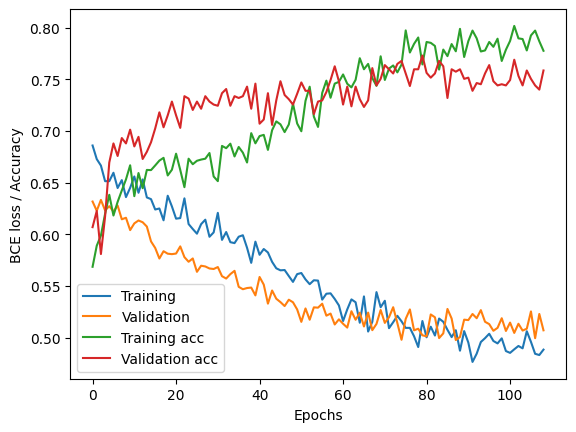

In [31]:
loss_fn = nn.BCELoss()

n_max_epochs = 300                           # The maximum number of epochs. Early stopping can end the training before this.
learning_rate = 0.001
batch_size = 32

# Early stopping: hyperparameter for patience
early_stopping_patience = 20

optimizer = torch.optim.Adam(bincl_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []

# Early stopping: init
best_bincl_model = None
best_val_loss = float('inf')
last_early_stopping_update_ep_idx = 0

for epoch_idx in range(n_max_epochs):

    # training
    bincl_model.train()                  # just setting a flag (setting our neural network model in a training mode)
    train_losses_in_epoch = []
    train_accs_in_epoch = []

    for train_batch_xs, train_batch_ys in dataloader_train:      # the DataLoader instance is an iterable; it provides a new iterator on an __iter__() call

        optimizer.zero_grad()
        train_batch_ys_pred = bincl_model(train_batch_xs)        # (batch_size OR smaller_last_batch_size, n_input_vars) -> (batch_size OR smaller_last_batch_size, 1)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)      # 'loss' always has to be a scalar
        acc = bin_acc_fn(train_batch_ys_pred, train_batch_ys)    # scalar

        train_losses_in_epoch.append(loss.detach())    # 'loss.detach()' tensor is stored in the list only, not the 'loss' tensor itself
                                                       #     to avoid keeping the now useless computational graph in memory,
                                                       #     connected to the tensors stored in the 'train_losses_in_epoch' list
        train_accs_in_epoch.append(acc)                # 'acc.detach()' is not needed, as the 'acc' tensor has no computational
                                                       #     graph connected to it, since it comes from a no_grad environment

        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    train_accs_in_epoch = torch.tensor(train_accs_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_tr_epoch_acc = train_accs_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)
    train_accuracy.append(avg_tr_epoch_acc)

    # validation
    bincl_model.eval()                  # just setting a flag (setting our neural network model in a non-training mode)
    val_losses_in_epoch = []
    val_accs_in_epoch = []

    for val_batch_xs, val_batch_ys in dataloader_val:      # the DataLoader instance is an iterable; it provides a new iterator on an __iter__() call

        with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
            val_batch_ys_pred = bincl_model(val_batch_xs)
        loss = loss_fn(val_batch_ys_pred, val_batch_ys)
        acc = bin_acc_fn(val_batch_ys_pred, val_batch_ys)

        val_losses_in_epoch.append(loss)    # 'loss.detach()' is not needed, again, as 'val_batch_ys_pred' was created in a no_grad environment
                                            #     therefore 'loss' has no computational graph connected to it either
        val_accs_in_epoch.append(acc)

    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    val_accs_in_epoch = torch.tensor(val_accs_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_val_epoch_acc = val_accs_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)
    val_accuracy.append(avg_val_epoch_acc)

    # logging
    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

    # Early stopping: check if current validation loss is the lowest ever; if yes, save current model parameters
    if avg_val_epoch_loss < best_val_loss:
        best_val_loss = avg_val_epoch_loss
        best_bincl_model = copy.deepcopy(bincl_model)
        last_early_stopping_update_ep_idx = epoch_idx
        print("    Early stopping: Best model updated.")

    # Early stopping: end training if no new lowest validation loss value occurred for a long time
    if last_early_stopping_update_ep_idx + early_stopping_patience < epoch_idx:
        print("Training is terminated by early stopping.")
        break

    # (end of training loop)

# Early stopping: restore the best model parameters (these correspond to the epoch where the validation loss was the lowest)
print("Training finished. Best model weights are restored.")
bincl_model = best_bincl_model

# training has finished; evaluate trained model on test set (measure loss, accuracy on test set)
test_ys_preds = []
test_ys = []

for test_batch_xs, test_batch_ys in dataloader_test:      # the DataLoader instance is an iterable; it provides a new iterator on an __iter__() call

    with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
        test_batch_ys_pred = bincl_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)               # test_batch_ys_pred.detach() is not needed, again, as we are in a no_grad environment
        test_ys.append(test_batch_ys)

test_ys_preds = torch.cat(test_ys_preds, axis=0)
test_ys = torch.cat(test_ys, axis=0)
test_loss = loss_fn(test_ys_preds, test_ys)
test_acc = bin_acc_fn(test_ys_preds, test_ys)

print(f"Test loss: {test_loss}, test acc: {test_acc}")

# Plot training/val curves
plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss / Accuracy')
plt.legend()
plt.show()


We reach a binary accuracy of around 80% on the test set. **The results are hard to interpret as we haven't accounted for the non-uniform distribution of categories** (the different number of passengers surviving and dying).